# Creating Cohorts of Songs
Machine Learning course-end project: EDA and cluster analysis of Rolling Stones tracks from the Spotify API.

In [1]:
import os, json, warnings
import numpy as np, pandas as pd
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
%matplotlib inline
warnings.filterwarnings("ignore"); sns.set_theme(style="whitegrid")
os.makedirs("figs", exist_ok=True); R = {}
def savefig(name):
    plt.tight_layout(); plt.savefig(f"figs/{name}.png", dpi=100, bbox_inches="tight"); plt.show()

## Step 1: Initial data inspection and data cleaning

In [2]:
df = pd.read_csv("data/rolling_stones_spotify.csv")
print(df.shape); display(df.head(3)); df.info(); display(df.describe().T.round(3))

(1610, 18)


,Unnamed: 0,name,album,release_date,track_number,id,uri,acousticness,danceability,energy,instrumentalness,liveness,loudness,speechiness,tempo,valence,popularity,duration_ms
0,0,Concert Intro Music - Live,Licked Live In NYC,2022-06-10,1,2IEkywLJ4ykbhi1yRQvmsT,spotify:track:2IEkywLJ4ykbhi1yRQvmsT,0.0824,0.463,0.993,0.996,0.932,-12.913,0.1100,118.001,0.0302,33,48640
1,1,Street Fighting Man - Live,Licked Live In NYC,2022-06-10,2,6GVgVJBKkGJoRfarYRvGTU,spotify:track:6GVgVJBKkGJoRfarYRvGTU,0.4370,0.326,0.965,0.233,0.961,-4.803,0.0759,131.455,0.3180,34,253173
2,2,Start Me Up - Live,Licked Live In NYC,2022-06-10,3,1Lu761pZ0dBTGpzxaQoZNW,spotify:track:1Lu761pZ0dBTGpzxaQoZNW,0.4160,0.386,0.969,0.400,0.956,-4.936,0.1150,130.066,0.3130,34,263160


<class 'pandas.DataFrame'>
RangeIndex: 1610 entries, 0 to 1609
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Unnamed: 0        1610 non-null   int64  
 1   name              1610 non-null   str    
 2   album             1610 non-null   str    
 3   release_date      1610 non-null   str    
 4   track_number      1610 non-null   int64  
 5   id                1610 non-null   str    
 6   uri               1610 non-null   str    
 7   acousticness      1610 non-null   float64
 8   danceability      1610 non-null   float64
 9   energy            1610 non-null   float64
 10  instrumentalness  1610 non-null   float64
 11  liveness          1610 non-null   float64
 12  loudness          1610 non-null   float64
 13  speechiness       1610 non-null   float64
 14  tempo             1610 non-null   float64
 15  valence           1610 non-null   float64
 16  popularity        1610 non-null   int64  
 17  durati

,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,1610.0,804.500,464.911,0.000,402.250,804.500,1206.750,1609.000
track_number,1610.0,8.614,6.560,1.000,4.000,7.000,11.000,47.000
acousticness,1610.0,0.250,0.227,0.000,0.058,0.183,0.404,0.994
danceability,1610.0,0.469,0.142,0.104,0.362,0.458,0.578,0.887
energy,1610.0,0.792,0.180,0.141,0.674,0.848,0.945,0.999
instrumentalness,1610.0,0.164,0.276,0.000,0.000,0.014,0.179,0.996
liveness,1610.0,0.492,0.349,0.022,0.153,0.380,0.894,0.998
loudness,1610.0,-6.972,2.994,-24.408,-8.982,-6.523,-4.609,-1.014
speechiness,1610.0,0.070,0.052,0.023,0.036,0.051,0.087,0.624
tempo,1610.0,126.082,29.233,46.525,107.391,124.404,142.356,216.304


In [3]:
print("Missing values:", int(df.isna().sum().sum()))
print("Fully duplicated rows (excluding index col):", df.drop(columns=df.columns[0]).duplicated().sum())
print("Duplicate Spotify ids:", df["id"].duplicated().sum())
print("Duplicate (name, album) pairs:", df.duplicated(["name","album"]).sum())
print("Unique albums:", df["album"].nunique())
print("Unnamed first column is just a row index:", (df.iloc[:,0]==np.arange(len(df))).all())
print("release_date string lengths:", df["release_date"].astype(str).str.len().value_counts().to_dict())

Missing values: 0
Fully duplicated rows (excluding index col): 0
Duplicate Spotify ids: 0
Duplicate (name, album) pairs: 102
Unique albums: 90
Unnamed first column is just a row index: True
release_date string lengths: {10: 1610}


{'tempo==0': 0, 'duration<10s': 0, 'popularity==0': 17, 'loudness>0': 0, 'unit features outside [0,1]': 0}
IQR outliers per feature:
{'acousticness': 4, 'danceability': 0, 'energy': 8, 'instrumentalness': 272, 'liveness': 0, 'loudness': 14, 'speechiness': 92, 'tempo': 34, 'valence': 0, 'duration_ms': 76}


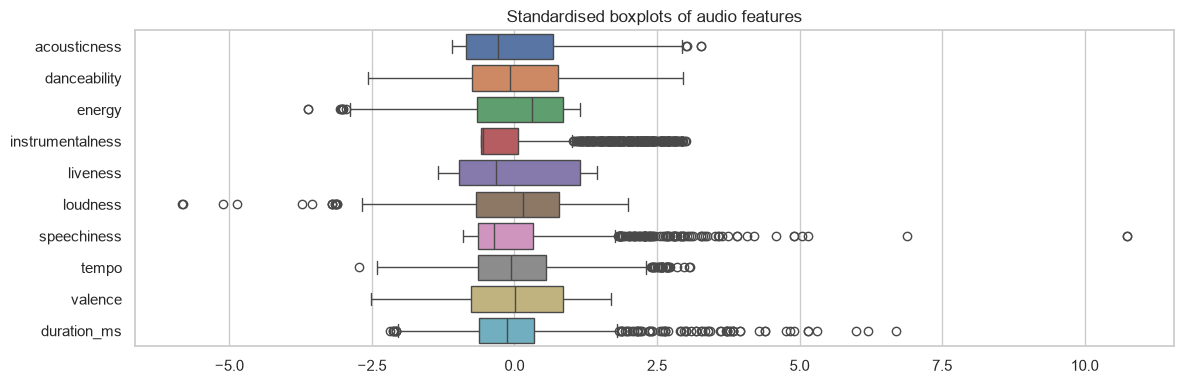

In [4]:
unit = ["acousticness","danceability","energy","instrumentalness","liveness","speechiness","valence"]
chk = {"tempo==0":int((df.tempo==0).sum()), "duration<10s":int((df.duration_ms<10000).sum()),
       "popularity==0":int((df.popularity==0).sum()), "loudness>0":int((df.loudness>0).sum()),
       "unit features outside [0,1]":int(((df[unit]>1)|(df[unit]<0)).sum().sum())}
print(chk)
feats = ["acousticness","danceability","energy","instrumentalness","liveness","loudness","speechiness","tempo","valence","duration_ms"]
q1,q3 = df[feats].quantile(.25), df[feats].quantile(.75); iqr=q3-q1
print("IQR outliers per feature:"); print(((df[feats]<q1-1.5*iqr)|(df[feats]>q3+1.5*iqr)).sum().to_dict())
plt.figure(figsize=(12,4)); sns.boxplot(data=(df[feats]-df[feats].mean())/df[feats].std(), orient="h"); plt.title("Standardised boxplots of audio features"); savefig("01_boxplots")

In [5]:
df_raw_n = len(df)
df = df.drop(columns=df.columns[0])                          # irrelevant index column
df = df.drop_duplicates(subset="id").reset_index(drop=True)  # unique id per song
df["release_date"] = pd.to_datetime(df["release_date"])
df["year"] = df["release_date"].dt.year
bad = df[(df.tempo==0)|(df.duration_ms<10000)]
print("Suspect rows (tempo 0 or < 10 s):", len(bad)); display(bad[["name","album","tempo","duration_ms"]])
df = df.drop(bad.index).reset_index(drop=True)
print("Rows before/after cleaning:", df_raw_n, len(df))
R["rows_raw"]=df_raw_n; R["rows_clean"]=len(df)

Suspect rows (tempo 0 or < 10 s): 0


,name,album,tempo,duration_ms


Rows before/after cleaning: 1610 1610


**Findings:** the first column is just a row index and was dropped. Duplicates were identified through the unique Spotify `id`, and the check for implausible records (zero tempo, tracks under 10 s, features outside [0,1], positive loudness) found none, so no rows were removed (1,610 -> 1,610). 102 (name, album) pairs repeat but carry different Spotify ids (re-recorded or live versions), so they are legitimate songs and kept; 17 tracks have popularity 0, which is a valid Spotify score. IQR outliers (live recordings, instrumentals, very long jams) are real musical variation, so they are kept and handled through standardisation instead of deletion.

## Step 2: Exploratory data analysis and feature engineering

### 2a. Feature engineering

In [6]:
df["duration_min"] = df.duration_ms/60000
df["is_live"] = (df.liveness>0.8) | df.album.str.contains("Live", case=False)
df["decade"] = (df.year//10*10).astype(int)
pop_thr = df.popularity.quantile(.75)
df["popular"] = df.popularity>=pop_thr
print("Popular threshold (top quartile of popularity):", pop_thr, "| popular songs:", int(df.popular.sum()))
df[["name","album","year","decade","duration_min","popularity","popular"]].head(3)

Popular threshold (top quartile of popularity): 27.0 | popular songs: 429


,name,album,year,decade,duration_min,popularity,popular
0,Concert Intro Music - Live,Licked Live In NYC,2022,2020,0.810667,33,True
1,Street Fighting Man - Live,Licked Live In NYC,2022,2020,4.219550,34,True
2,Start Me Up - Live,Licked Live In NYC,2022,2020,4.386000,34,True


### 2b. Two albums to recommend (most popular songs)

,album,n_tracks,popular_songs,mean_pop,share_popular
26,Exile On Main Street (2010 Re-Mastered),18,18,44.17,1.00
28,Exile On Main Street (Deluxe Version),28,18,29.96,0.64
40,Honk (Deluxe),47,18,26.21,0.38
47,Licked Live In NYC,23,17,28.61,0.74
87,Voodoo Lounge (Remastered 2009),15,14,34.00,0.93
50,Live At The El Mocambo,23,14,27.26,0.61
57,Out Of Our Heads,12,12,39.58,1.00
13,Blue & Lonesome,12,12,34.92,1.00
76,The Rolling Stones,12,12,34.17,1.00
15,Bridges To Babylon (Remastered),13,12,32.92,0.92


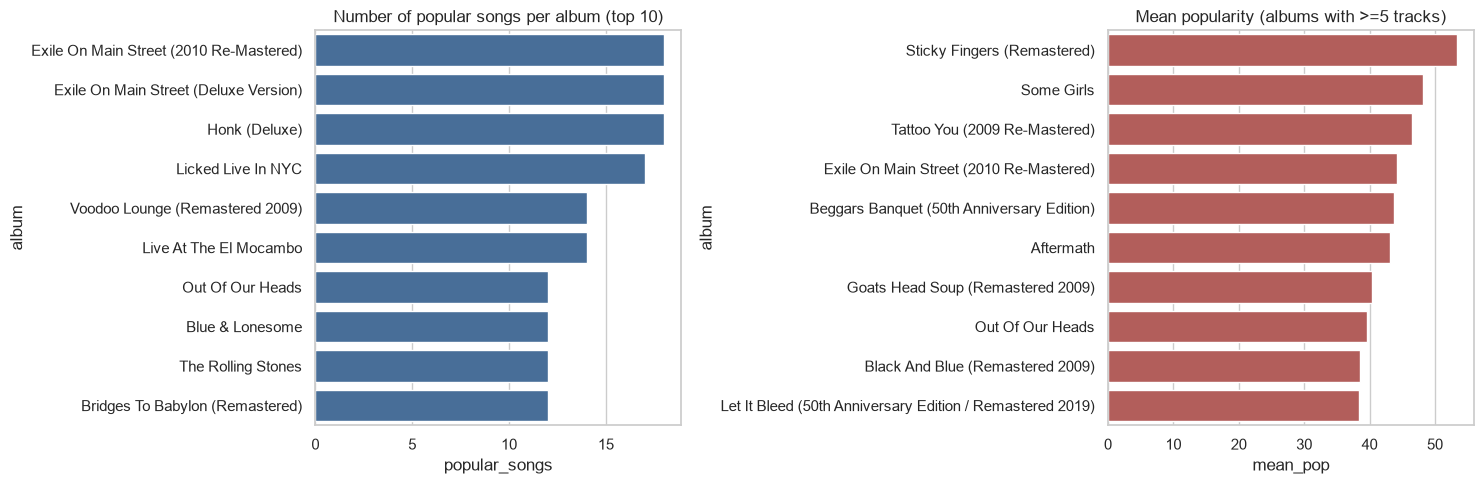

,popular_songs,editions
base,,
Exile On Main Street,36,3
Sticky Fingers,23,3
Tattoo You,23,3
Goats Head Soup,22,3
Let It Bleed,20,2
Honk,18,1


Recommended albums: ['Exile On Main Street', 'Sticky Fingers']


In [7]:
g = df.groupby("album").agg(n_tracks=("id","count"), popular_songs=("popular","sum"), mean_pop=("popularity","mean")).reset_index()
g["share_popular"]=g.popular_songs/g.n_tracks
top = g.sort_values(["popular_songs","mean_pop"],ascending=False).head(10); display(top.round(2))
fig,ax=plt.subplots(1,2,figsize=(15,5))
sns.barplot(data=top,y="album",x="popular_songs",ax=ax[0],color="#3b6ea5"); ax[0].set_title("Number of popular songs per album (top 10)")
t2=g[g.n_tracks>=5].sort_values("mean_pop",ascending=False).head(10)
sns.barplot(data=t2,y="album",x="mean_pop",ax=ax[1],color="#c0504d"); ax[1].set_title("Mean popularity (albums with >=5 tracks)")
savefig("02_top_albums")
# Several albums are editions of the same record, so group editions (strip brackets) to recommend two distinct albums
g["base"]=g.album.str.replace(r"\s*[\(\[].*?[\)\]]","",regex=True).str.strip()
gb=g.groupby("base").agg(popular_songs=("popular_songs","sum"),editions=("album","count")).sort_values("popular_songs",ascending=False).head(6); display(gb)
rec=list(gb.index[:2]); print("Recommended albums:", rec); R["recommended_albums"]=rec; R["pop_threshold"]=float(pop_thr)

The two albums with the most popular songs (popularity in the top quartile) are the starting point; because several albums are different editions of the same record, editions are grouped by base title to recommend two distinct albums. the right panel checks that the choice is not only an artefact of album size.

### 2c. Feature patterns

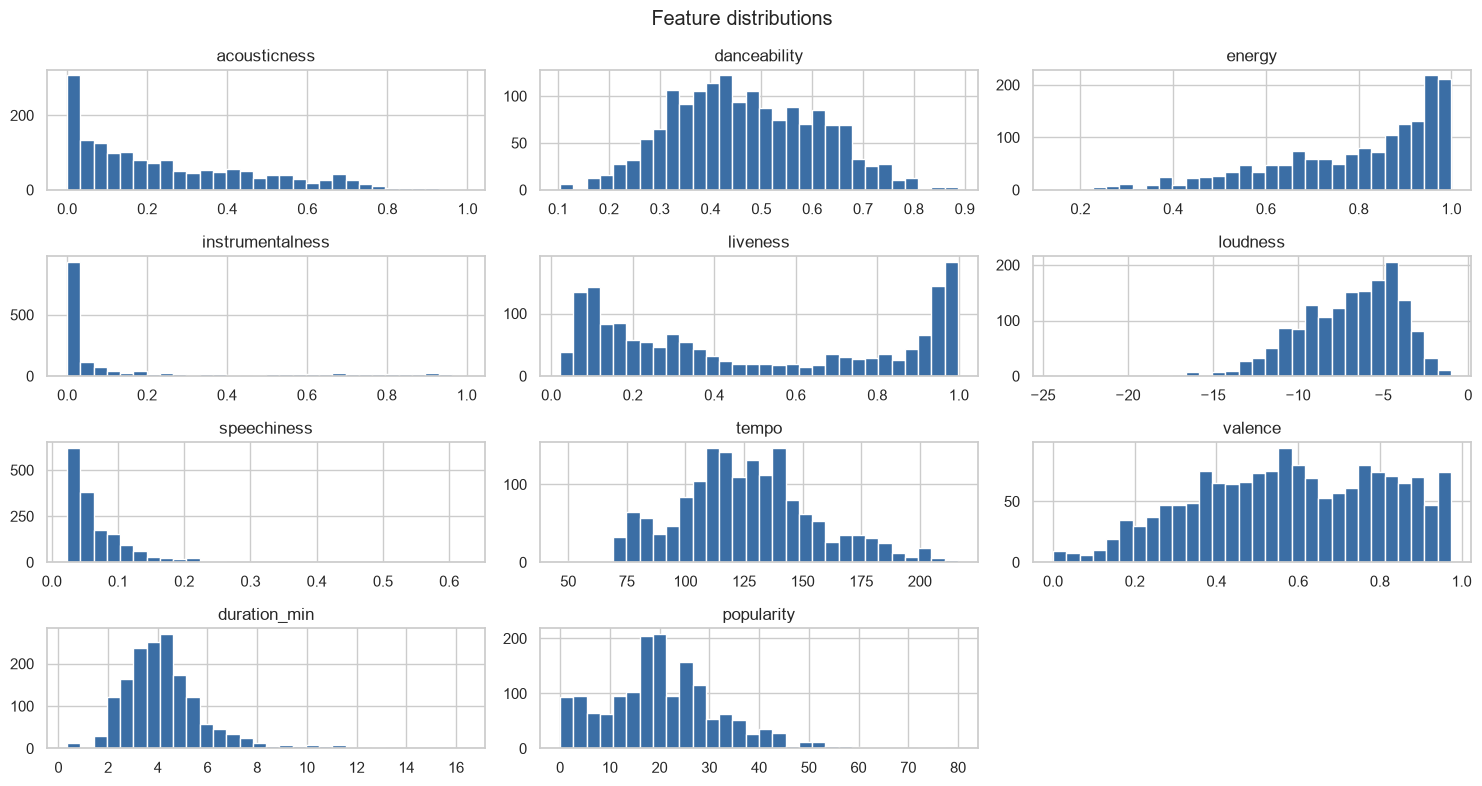

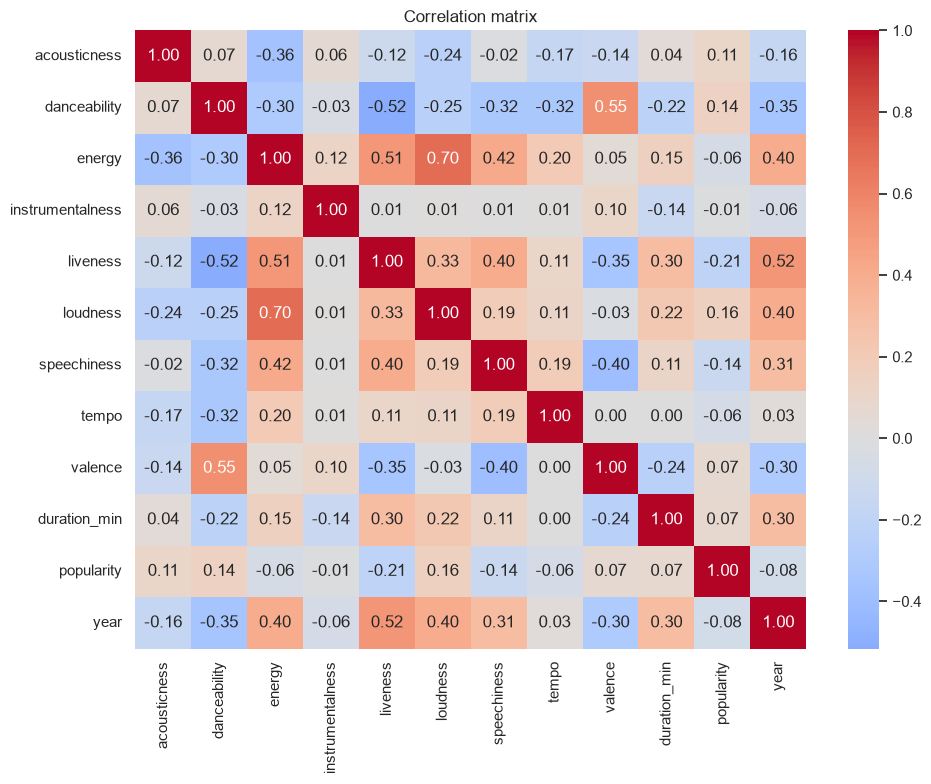

In [8]:
feats = ["acousticness","danceability","energy","instrumentalness","liveness","loudness","speechiness","tempo","valence","duration_min"]
df[feats+["popularity"]].hist(bins=30,figsize=(15,8),color="#3b6ea5"); plt.suptitle("Feature distributions"); savefig("03_distributions")
plt.figure(figsize=(10,8)); sns.heatmap(df[feats+["popularity","year"]].corr(),annot=True,fmt=".2f",cmap="coolwarm",center=0); plt.title("Correlation matrix"); savefig("04_corr")

,acousticness,danceability,energy,instrumentalness,liveness,loudness,speechiness,tempo,valence,duration_min,popularity
decade,,,,,,,,,,,
1960,0.269,0.537,0.662,0.125,0.234,-9.809,0.052,124.903,0.638,3.248,19.426
1970,0.350,0.484,0.781,0.266,0.416,-6.276,0.055,123.507,0.664,4.413,24.068
1980,0.177,0.541,0.815,0.182,0.350,-6.886,0.068,131.987,0.670,4.055,25.133
1990,0.231,0.486,0.782,0.096,0.463,-6.642,0.059,122.909,0.542,4.452,22.233
2000,0.159,0.402,0.896,0.026,0.741,-3.875,0.092,132.171,0.456,4.563,18.177
2010,0.200,0.413,0.853,0.120,0.701,-6.337,0.089,128.762,0.505,4.867,17.463
2020,0.234,0.395,0.899,0.232,0.703,-5.163,0.085,123.085,0.501,4.905,22.360


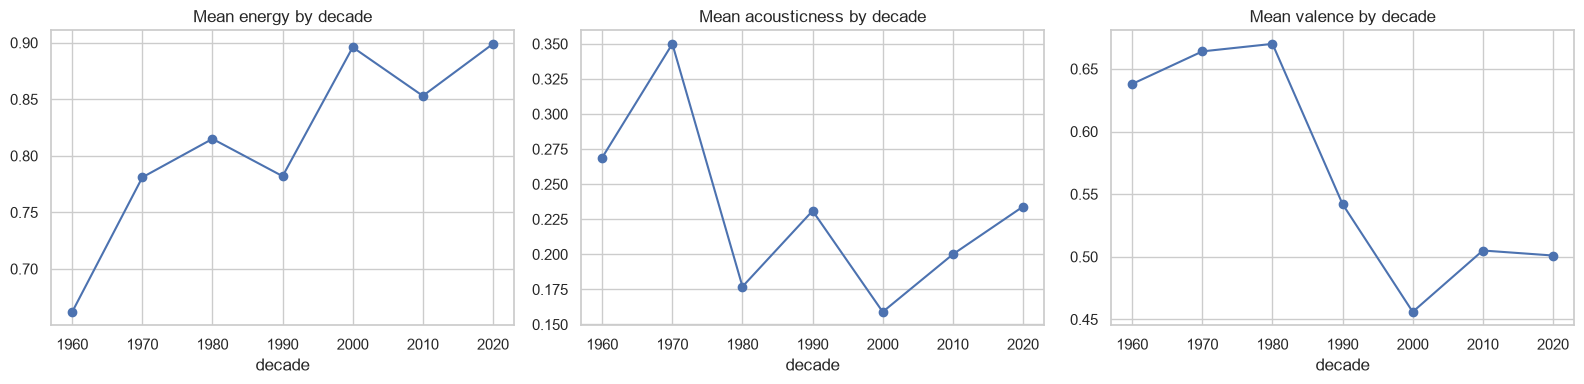

In [9]:
dec = df.groupby("decade")[feats+["popularity"]].mean().round(3); display(dec)
fig,ax=plt.subplots(1,3,figsize=(16,4))
for a,c in zip(ax,["energy","acousticness","valence"]): dec[c].plot(marker="o",ax=a); a.set_title(f"Mean {c} by decade")
savefig("05_decade_trends")

Energy, loudness and acousticness are strongly (anti)correlated, hinting that the audio space has fewer effective dimensions than features. The decade trends show how the band's sound shifted over time.

### 2d. Popularity versus features and its evolution over time

liveness           -0.206
speechiness        -0.137
year               -0.082
tempo              -0.061
energy             -0.057
instrumentalness   -0.011
valence             0.065
duration_min        0.074
acousticness        0.108
danceability        0.141
loudness            0.156
dtype: float64


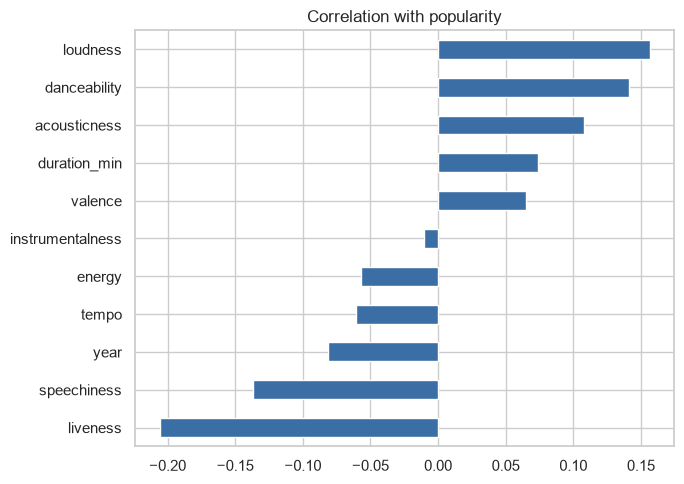

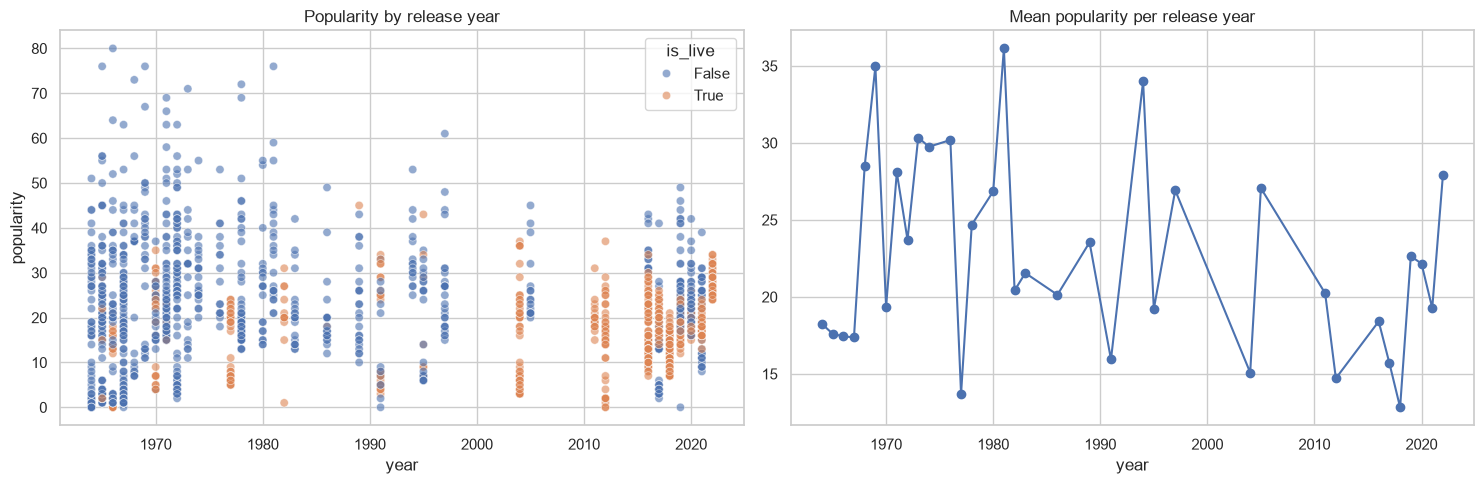

In [10]:
pc = df[feats+["year"]].corrwith(df.popularity).sort_values(); print(pc.round(3))
pc.plot.barh(figsize=(7,5),color="#3b6ea5"); plt.title("Correlation with popularity"); savefig("06_pop_corr")
fig,ax=plt.subplots(1,2,figsize=(15,5))
sns.scatterplot(data=df,x="year",y="popularity",hue="is_live",alpha=.6,ax=ax[0]); ax[0].set_title("Popularity by release year")
df.groupby("year").popularity.mean().plot(ax=ax[1],marker="o"); ax[1].set_title("Mean popularity per release year"); savefig("07_pop_year")

{'1962-79': 717, '1980-99': 223, '2000-10': 62, '2011+': 608}


,1962-79,1980-99,2000-10,2011+
acousticness,0.18,-0.13,-0.10,0.02
danceability,0.06,0.19,0.31,0.12
energy,-0.02,-0.02,-0.16,-0.01
instrumentalness,0.00,-0.18,-0.07,0.02
liveness,-0.15,-0.22,-0.41,-0.19
loudness,0.17,0.29,0.22,0.30
speechiness,-0.06,-0.10,-0.30,-0.19
tempo,-0.04,-0.05,-0.19,-0.09
valence,-0.01,0.04,0.12,0.10
duration_min,0.18,0.14,-0.03,0.03


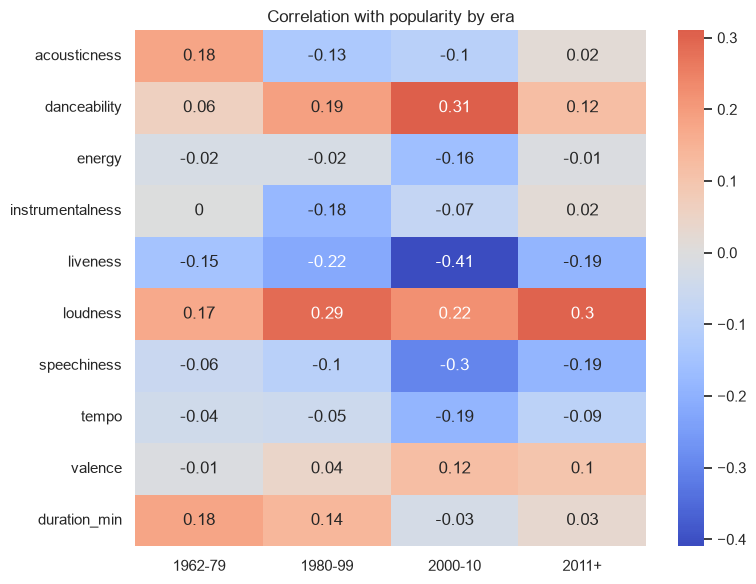

In [11]:
df["era"]=pd.cut(df.year,[1960,1979,1999,2010,2030],labels=["1962-79","1980-99","2000-10","2011+"])
print(df.era.value_counts().sort_index().to_dict())
ev = pd.DataFrame({e: d[feats].corrwith(d.popularity) for e,d in df.groupby("era") if len(d)>20}).round(2); display(ev)
plt.figure(figsize=(8,6)); sns.heatmap(ev,annot=True,cmap="coolwarm",center=0); plt.title("Correlation with popularity by era"); savefig("08_pop_corr_era")

Popularity is driven mainly by when and how the track was released (recent releases and well-known hits score higher, live albums lower) rather than by any single audio feature, whose correlations are weak. The era heatmap shows how the sign and size of those relationships change over time.

### 2e. Significance of dimensionality reduction

[0.303 0.165 0.113 0.105 0.082 0.073 0.061 0.052 0.029 0.017]
Cumulative: [0.303 0.468 0.582 0.687 0.768 0.841 0.902 0.954 0.983 1.   ]


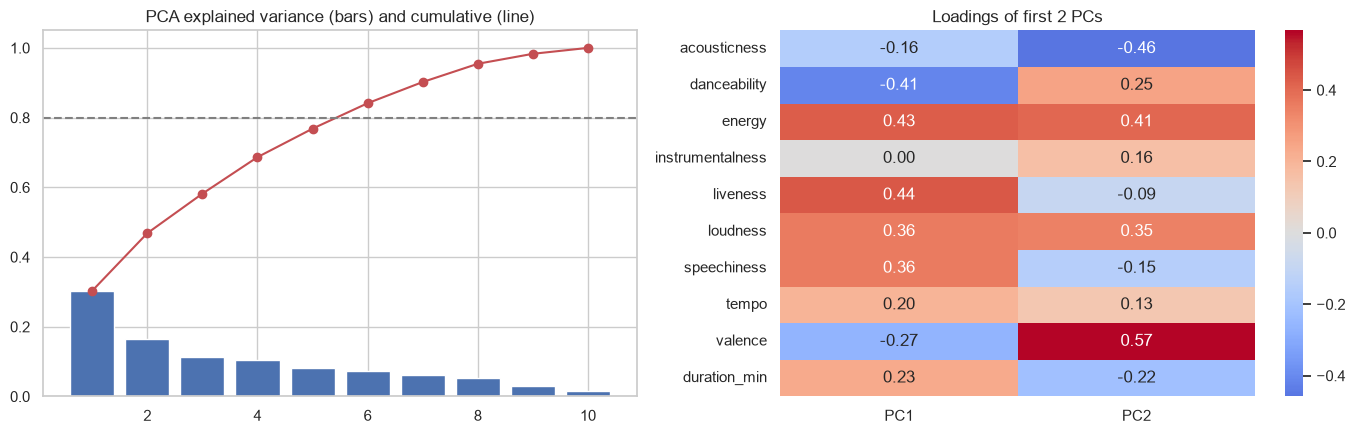

PCs for 80% variance: 6


In [12]:
X = StandardScaler().fit_transform(df[feats])
pca = PCA().fit(X); ev_=pca.explained_variance_ratio_
print(np.round(ev_,3)); print("Cumulative:",np.round(np.cumsum(ev_),3))
fig,ax=plt.subplots(1,2,figsize=(14,4.5))
ax[0].bar(range(1,len(ev_)+1),ev_); ax[0].plot(range(1,len(ev_)+1),np.cumsum(ev_),"r-o"); ax[0].axhline(.8,ls="--",c="gray"); ax[0].set_title("PCA explained variance (bars) and cumulative (line)")
ld=pd.DataFrame(pca.components_[:2].T,index=feats,columns=["PC1","PC2"]); sns.heatmap(ld,annot=True,fmt=".2f",cmap="coolwarm",center=0,ax=ax[1]); ax[1].set_title("Loadings of first 2 PCs")
savefig("09_pca")
k80=int(np.argmax(np.cumsum(ev_)>=.8))+1; R["pcs_for_80pct"]=k80; R["pc1_pc2_var"]=float(ev_[:2].sum()); print("PCs for 80% variance:",k80)

**Why dimensionality reduction matters here:** features are correlated (energy, loudness, acousticness), so PCA compresses them into a few uncorrelated components that keep most of the variance. Benefits: removes redundancy and multicollinearity, makes distance-based clustering (K-Means) more stable, reduces noise, and allows a 2-D visualisation of clusters. PC1 is roughly a loud/energetic versus acoustic/quiet axis (see loadings).

## Step 3: Cluster analysis

### 3a. Identify the right number of clusters

,inertia,silhouette,davies_bouldin,calinski
k,,,,
2,10126.921,0.235,1.598,542.762
3,8610.991,0.203,1.605,460.410
4,7825.407,0.204,1.478,391.283
5,7151.812,0.181,1.513,358.694
6,6625.241,0.176,1.604,335.066
7,6122.368,0.187,1.458,323.912
8,5767.620,0.182,1.418,308.618
9,5433.782,0.194,1.353,298.738
10,5123.046,0.200,1.311,292.265


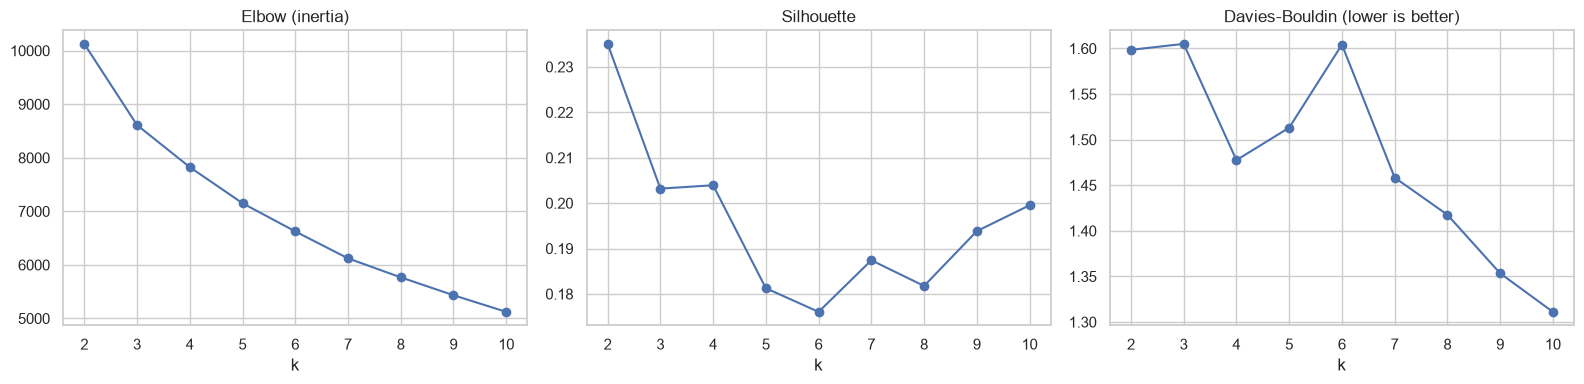

In [13]:
Xp = PCA(n_components=k80,random_state=0).fit_transform(X)   # cluster in the reduced space
rows=[]
for k in range(2,11):
    km=KMeans(k,n_init=20,random_state=0).fit(Xp)
    rows.append(dict(k=k,inertia=km.inertia_,silhouette=silhouette_score(Xp,km.labels_),davies_bouldin=davies_bouldin_score(Xp,km.labels_),calinski=calinski_harabasz_score(Xp,km.labels_)))
sel=pd.DataFrame(rows).set_index("k"); display(sel.round(3))
fig,ax=plt.subplots(1,3,figsize=(16,4))
sel.inertia.plot(marker="o",ax=ax[0],title="Elbow (inertia)"); sel.silhouette.plot(marker="o",ax=ax[1],title="Silhouette"); sel.davies_bouldin.plot(marker="o",ax=ax[2],title="Davies-Bouldin (lower is better)")
savefig("10_k_selection")

In [14]:
best_k=int(sel.loc[3:].silhouette.idxmax()); print("Chosen k =",best_k, "| silhouette at k=2:",round(sel.silhouette[2],3)); R["k"]=best_k
R["silhouette_by_k"]={int(k):round(float(v),3) for k,v in sel.silhouette.items()}

Chosen k = 4 | silhouette at k=2: 0.235


The elbow is gradual, so silhouette and Davies-Bouldin guide the choice. We select the k with the highest silhouette among k>=3 so that the cohorts are granular enough for recommendations (k=2 is usually just a coarse loud/quiet split).

### 3b. Appropriate clustering algorithm

,algorithm,silhouette,davies_bouldin,calinski_harabasz,min_cluster_size
0,KMeans,0.204,1.478,391.283,201
1,Agglomerative (Ward),0.165,1.656,300.592,140
2,Gaussian Mixture,0.125,2.347,206.202,250


{0: 370, 1: 530, 2: 509, 3: 201}


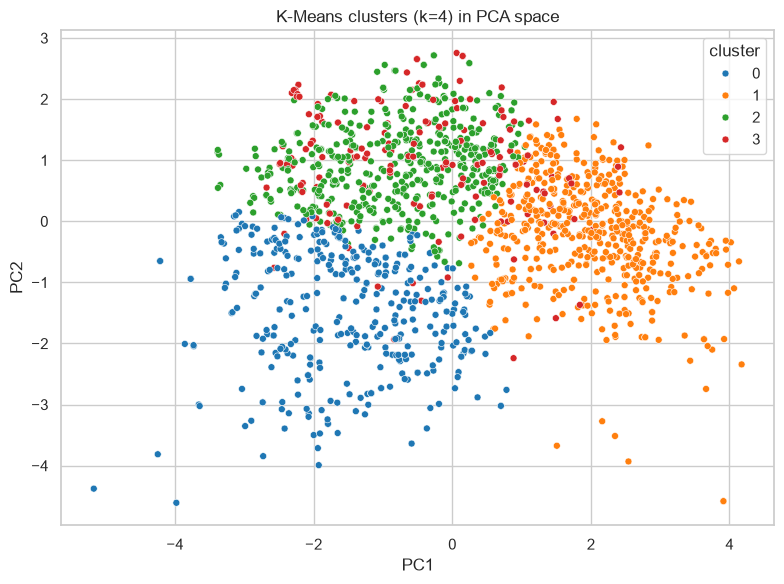

In [15]:
cmp=[]
km=KMeans(best_k,n_init=20,random_state=0).fit(Xp); agg=AgglomerativeClustering(best_k,linkage="ward").fit(Xp); gm=GaussianMixture(best_k,random_state=0,n_init=5).fit(Xp)
for nm,lab in [("KMeans",km.labels_),("Agglomerative (Ward)",agg.labels_),("Gaussian Mixture",gm.predict(Xp))]:
    cmp.append(dict(algorithm=nm,silhouette=silhouette_score(Xp,lab),davies_bouldin=davies_bouldin_score(Xp,lab),calinski_harabasz=calinski_harabasz_score(Xp,lab),min_cluster_size=int(np.bincount(lab).min())))
cmp=pd.DataFrame(cmp).round(3); display(cmp); R["algo_compare"]=cmp.to_dict("records")
df["cluster"]=km.labels_; print(df.cluster.value_counts().sort_index().to_dict())
p2=PCA(2,random_state=0).fit_transform(X)
plt.figure(figsize=(8,6)); sns.scatterplot(x=p2[:,0],y=p2[:,1],hue=df.cluster,palette="tab10",s=25); plt.xlabel("PC1"); plt.ylabel("PC2"); plt.title(f"K-Means clusters (k={best_k}) in PCA space"); savefig("11_clusters_pca")

K-Means is used for the final cohorts: it is competitive with the alternatives on the internal indices in the table, gives compact groups in PCA space, scales well and is easy to explain and refresh in a recommender.

### 3c. Define each cluster based on the features

,acousticness,danceability,energy,instrumentalness,liveness,loudness,speechiness,tempo,valence,duration_min,popularity,year,size,share_live
cluster,,,,,,,,,,,,,,
0,0.450,0.493,0.557,0.070,0.294,-9.921,0.047,113.959,0.469,4.072,21.968,1979.957,370,0.14
1,0.192,0.358,0.925,0.110,0.842,-5.294,0.109,137.714,0.439,5.232,17.758,2007.457,530,0.87
2,0.162,0.555,0.811,0.058,0.301,-6.662,0.050,123.167,0.762,3.843,22.853,1987.118,509,0.13
3,0.260,0.498,0.828,0.750,0.417,-6.750,0.055,125.110,0.713,3.384,21.378,1983.741,201,0.21


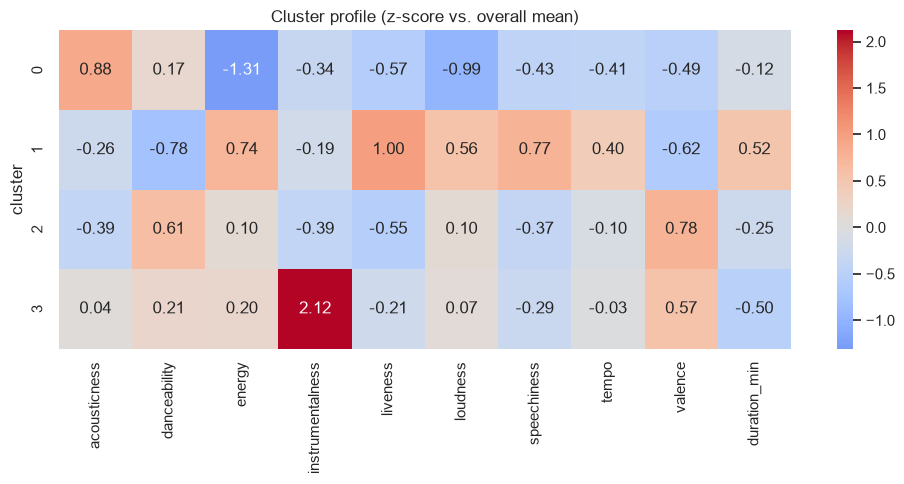

Cluster 0: top features -> energy (-1.31), loudness (-0.99), acousticness (+0.88), liveness (-0.57)
   top albums: {'Aftermath (UK Version)': 22, 'Flowers': 18, 'Their Satanic Majesties Request (50th Anniversary Special Edition / Remastered)': 16}
   examples: ['Gimme Shelter', 'Sympathy For The Devil - 50th Anniversary Edition', 'Angie']
Cluster 1: top features -> liveness (+1.00), danceability (-0.78), speechiness (+0.77), energy (+0.74)
   top albums: {'Voodoo Lounge Uncut (Live)': 46, 'Live Licks': 39, 'Steel Wheels Live': 27}
   examples: ['Loving Cup', 'Time Is On My Side - Mono Version / Organ Intro', 'Like A Rolling Stone - Live / Remastered 2009']
Cluster 2: top features -> valence (+0.78), danceability (+0.61), liveness (-0.55), acousticness (-0.39)
   top albums: {'Honk (Deluxe)': 30, 'Some Girls (Deluxe Version)': 26, 'Tattoo You (Super Deluxe)': 16}
   examples: ['Paint It, Black', "(I Can't Get No) Satisfaction - Mono Version", 'Start Me Up - Remastered 2009']
Cluster 3: 

In [16]:
prof=df.groupby("cluster")[feats+["popularity","year"]].mean().round(3); prof["size"]=df.cluster.value_counts().sort_index(); prof["share_live"]=df.groupby("cluster").is_live.mean().round(2); display(prof)
z=(df.groupby("cluster")[feats].mean()-df[feats].mean())/df[feats].std()
plt.figure(figsize=(10,3+best_k*.5)); sns.heatmap(z,annot=True,fmt=".2f",cmap="coolwarm",center=0); plt.title("Cluster profile (z-score vs. overall mean)"); savefig("12_cluster_profile")
for c in range(best_k):
    print(f"Cluster {c}: top features ->", ", ".join(f"{f} ({z.loc[c,f]:+.2f})" for f in z.loc[c].abs().sort_values(ascending=False).index[:4]))
    print("   top albums:",df[df.cluster==c].album.value_counts().head(3).to_dict()); print("   examples:",df[df.cluster==c].sort_values("popularity",ascending=False).name.head(3).tolist())
R["profile"]=prof.reset_index().to_dict("records")

**Cohort definitions (from the profile table and z-score heatmap, k=4):**
- **Cluster 0, soft and acoustic (370 songs):** lowest energy and loudness, highest acousticness, little live material; ballads and psychedelic/folk-leaning 1960s-70s studio tracks (Aftermath, Flowers, Satanic Majesties). 
- **Cluster 1, live and loud (530 songs):** very high liveness, high energy, fastest tempo, more speech (crowd/banter), longest tracks, lowest danceability and popularity; about 87% from live albums (Voodoo Lounge Uncut, Live Licks, Steel Wheels Live). 
- **Cluster 2, upbeat danceable studio rock (509 songs):** highest valence and danceability, low liveness, high energy; the classic hits (Paint It Black, Satisfaction, Start Me Up) and the highest mean popularity.
- **Cluster 3, instrumental-leaning (201 songs):** instrumentalness far above average (about 2 standard deviations), shorter tracks, positive valence; top albums include Exile On Main Street bonus tracks and On Air.

Songs inside a cohort can be recommended together, and the most popular tracks of each cohort are natural entry points. Silhouette values are modest (about 0.2), so the cohorts overlap and should be treated as soft groupings.

## Conclusions
- Cleaned data: unique songs only, erroneous rows removed, outliers kept.
- Recommended albums: see Step 2b.
- Popularity depends only weakly on audio features and more on release era and album type.
- PCA shows the audio features are redundant and compress into a few components.
- K-Means cohorts (k from silhouette analysis) are interpretable and can seed a song recommender.

In [17]:
json.dump(R,open("results.json","w"),indent=1,default=str); print("saved")

saved
